# Intelligent Document Assistant: Building a Retrieval-Augmented Generation (RAG) System

**Course project – Deep Learning / NLP (5th year, Computer Science Engineering – Artificial Intelligence)**

This notebook implements an end-to-end RAG pipeline that runs in Google Colab:

`PDF upload → extraction → cleaning → chunking → embeddings → FAISS index → retrieval → grounded generation → evaluation`

**Stack:** Python · PyMuPDF · Sentence Transformers · FAISS · Hugging Face Transformers · PyTorch · NumPy · Pandas · Matplotlib · Gradio


## STEP 1 — Environment setup

We install the libraries and print the hardware so that every experiment can be reproduced and reported together with its environment.
`torch` is pre-installed in Colab, so `pip` keeps the Colab build (important for GPU compatibility). `faiss-cpu` is enough for the index sizes used here (exact search).

In [1]:
!pip install -q pymupdf sentence-transformers faiss-cpu transformers accelerate torch numpy pandas matplotlib tqdm gradio

In [2]:
import os, sys, re, gc, json, time, math, random, platform, warnings
from pathlib import Path
from dataclasses import dataclass
from typing import List, Dict, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
try:
    import pymupdf as fitz        # PyMuPDF (current module name)
except ImportError:
    import fitz                  # older PyMuPDF releases
import faiss
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForCausalLM

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def print_environment():
    import transformers, sentence_transformers
    print("Python               :", sys.version.split()[0])
    print("Platform             :", platform.platform())
    print("PyTorch              :", torch.__version__)
    print("Transformers         :", transformers.__version__)
    print("Sentence-Transformers:", sentence_transformers.__version__)
    print("FAISS                :", getattr(faiss, "__version__", "unknown"))
    print("PyMuPDF              :", getattr(fitz, "VersionBind", "unknown"))
    print("Device               :", DEVICE)
    if torch.cuda.is_available():
        props = torch.cuda.get_device_properties(0)
        print(f"GPU                  : {props.name} ({props.total_memory / 1e9:.1f} GB)")
    else:
        print("GPU                  : not available -> CPU mode (slow for a 3B model). "
              "Use Runtime > Change runtime type > GPU.")
    try:
        import psutil
        vm = psutil.virtual_memory()
        print(f"System RAM           : {vm.total / 1e9:.1f} GB total, {vm.available / 1e9:.1f} GB available")
    except ImportError:
        pass


print_environment()

Python               : 3.13.16
Platform             : Linux-6.6.159+-x86_64-with-glibc2.39
PyTorch              : 2.14.1+cu130
Transformers         : 5.22.1
Sentence-Transformers: 5.7.0
FAISS                : 1.16.0
PyMuPDF              : 2.1
Device               : cuda
GPU                  : Tesla T4 (15.6 GB)
System RAM           : 13.6 GB total, 10.4 GB available


### Global configuration

All tunable parameters are in one place. The **baseline** values follow the course presentation (900-character chunks, 150 overlap, `top_k = 4`, `paraphrase-multilingual-MiniLM-L12-v2`, `Qwen2.5-3B-Instruct`).

* `ALLOW_FALLBACK`: if the 3B model does not fit in memory, the notebook may switch to the smaller documented fallback model. The switch is **never silent**: it is printed, and the model actually used is stored in `ACTIVE_GENERATION_MODEL` and reported with results.
* `MIN_SIMILARITY`: optional retrieval-score threshold below which the system abstains *without calling the LLM*. It is disabled (`None`) by default because a sensible value depends on the corpus; Step 13 shows how to calibrate it.
* `DEMO_QUESTIONS` / the evaluation set in Step 13 are written for the course guide **`RAG_Detailed.pdf`**. If you upload other documents, edit them.

In [3]:
# ---------- paths ----------
DATA_DIR = Path("data/documents")        # uploaded PDFs are stored here
ARTIFACT_DIR = Path("artifacts")         # FAISS index, chunks.json, evaluation exports
DATA_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# ---------- models ----------
EMBEDDING_MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
GENERATION_MODEL_NAME = "Qwen/Qwen2.5-3B-Instruct"                 # course baseline
FALLBACK_GENERATION_MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"      # documented smaller fallback
ALLOW_FALLBACK = True

# ---------- baseline RAG parameters (from the course presentation) ----------
CHUNK_SIZE = 900
CHUNK_OVERLAP = 150
TOP_K = 4
MAX_NEW_TOKENS = 300
MIN_SIMILARITY = None                    # e.g. 0.25 to abstain on weak retrieval (see Step 13)

# ---------- demonstration questions (for RAG_Detailed.pdf) ----------
DEMO_QUESTIONS = [
    # answerable
    "What chunk size and overlap does the guide recommend as starting values?",
    "What does IndexFlatIP compute, and why does it match cosine similarity?",
    "How is Mean Reciprocal Rank (MRR) calculated?",
    "Which language model does the guide use for generation, and what should I check on its model card?",
    "What should I do if the text extracted from a PDF is empty?",
    # NOT answerable from the guide -> the system should abstain
    "What is the capital city of Australia?",
    "What accuracy did the guide report for Qwen2.5-3B-Instruct on the MMLU benchmark?",
]
print("Configuration loaded.")

Configuration loaded.


## STEP 2 — PDF document upload

The knowledge base is built from PDFs uploaded through the Colab file picker (no hard-coded paths).
Every file is checked: extension must be `.pdf`, the file must be non-empty, openable by PyMuPDF, not password-protected and contain at least one page. Invalid files are reported and discarded; valid ones keep their **original filename**, which is later used as the source identifier. Several PDFs form one knowledge base.

If you run the notebook outside Colab, simply copy PDFs into `data/documents/` and run the second cell.

In [4]:
def validate_pdf(path):
    """Return (is_valid, message) for a candidate PDF file."""
    path = Path(path)
    try:
        if path.stat().st_size == 0:
            return False, "empty file (0 bytes)"
        with fitz.open(path) as pdf:
            if pdf.page_count == 0:
                return False, "PDF contains no pages"
            if pdf.needs_pass:
                return False, "PDF is password-protected"
        return True, "ok"
    except Exception as exc:  # corrupted / not a PDF
        return False, f"cannot be opened as a PDF ({exc})"


ALLOWED_EXTENSIONS = {".pdf"}


def upload_pdfs():
    # Open the Colab upload dialog and store valid PDFs in DATA_DIR. Returns accepted paths.
    try:
        from google.colab import files
    except ImportError:
        print("Not running in Colab: copy your PDFs into", DATA_DIR.resolve())
        return []
    uploaded = files.upload()                      # {filename: bytes}
    accepted = []
    for name, content in uploaded.items():
        safe_name = Path(name).name
        if Path(safe_name).suffix.lower() not in ALLOWED_EXTENSIONS:
            print(f"[rejected] {safe_name}: only .pdf files are accepted")
            continue
        target = DATA_DIR / safe_name
        target.write_bytes(content)
        ok, msg = validate_pdf(target)
        if ok:
            accepted.append(target)
            print(f"[accepted] {safe_name} ({len(content) / 1024:.0f} KB)")
        else:
            target.unlink(missing_ok=True)
            print(f"[rejected] {safe_name}: {msg}")
    return accepted


def collect_pdf_paths():
    # All valid PDFs currently stored in DATA_DIR (the knowledge base).
    valid = []
    for path in sorted(DATA_DIR.glob("*.pdf")):
        ok, msg = validate_pdf(path)
        if ok:
            valid.append(path)
        else:
            print(f"[skipped] {path.name}: {msg}")
    return valid

In [5]:
# >>> ACTION REQUIRED: choose one or more PDF files in the dialog (e.g. RAG_Detailed.pdf) <<<
_ = upload_pdfs()

pdf_paths = collect_pdf_paths()
if not pdf_paths:
    raise RuntimeError("No valid PDF found. Run this cell again and upload at least one PDF.")
print(f"\nKnowledge base: {len(pdf_paths)} PDF file(s)")
for p in pdf_paths:
    print("  -", p.name)

Saving ComprendreleRAGVersuneIAquiinterrogevosdocumentsintelligemment.pdf to ComprendreleRAGVersuneIAquiinterrogevosdocumentsintelligemment (1).pdf
Saving RAG.pdf to RAG (1).pdf
Saving RAG_Detailed.pdf to RAG_Detailed (1).pdf
Saving RAGEXPLANATION.pdf to RAGEXPLANATION (1).pdf
[accepted] ComprendreleRAGVersuneIAquiinterrogevosdocumentsintelligemment (1).pdf (3587 KB)
[accepted] RAG (1).pdf (7788 KB)
[accepted] RAG_Detailed (1).pdf (829 KB)
[accepted] RAGEXPLANATION (1).pdf (2938 KB)

Knowledge base: 13 PDF file(s)
  - 1.-La-définition-du-domaine-RI_chap1.pdf
  - 2.-introduction-RI.pdf
  - 3.-modeles-RI-1.pdf
  - 3.1-difference-entre-modèle-booléen-et-le-modèle-vectoriel.pdf
  - 4.-modele-p-norme.pdf
  - ComprendreleRAGVersuneIAquiinterrogevosdocumentsintelligemment (1).pdf
  - ComprendreleRAGVersuneIAquiinterrogevosdocumentsintelligemment.pdf
  - RAG (1).pdf
  - RAG.pdf
  - RAGEXPLANATION (1).pdf
  - RAGEXPLANATION.pdf
  - RAG_Detailed (1).pdf
  - RAG_Detailed.pdf


## STEP 3 — PDF text extraction (PyMuPDF)

**Purpose.** Convert each PDF into text units that keep their provenance: `(source filename, page number, text)`. Page numbers are *physical* PDF page indices starting at 1 (they may differ from page numbers printed on the page).

**Limitations to check, not to hide.**
* Scanned PDFs contain images instead of text. PyMuPDF does not perform OCR, so such pages come back empty. The function therefore counts empty pages (and empty pages that contain images) and raises an **OCR warning**; the notebook never claims that such documents were processed correctly.
* Tables may lose their row/column structure, and multi-column or equation-heavy layouts may be read in an unexpected order.

In [6]:
def extract_pdf_pages(pdf_path):
    """Extract text page by page with PyMuPDF.

    Returns
    -------
    pages  : list of dicts {text, source, page}  (pages with selectable text only)
    report : dict with per-document extraction statistics (used to flag possible OCR needs)
    """
    pdf_path = Path(pdf_path)
    pages, empty_pages, empty_with_images = [], 0, 0
    with fitz.open(pdf_path) as pdf:
        total_pages = pdf.page_count
        for page_number, page in enumerate(pdf, start=1):   # physical page index, starting at 1
            text = page.get_text("text").strip()
            if text:
                pages.append({"text": text, "source": pdf_path.name, "page": page_number})
            else:
                empty_pages += 1
                if page.get_images(full=True):
                    empty_with_images += 1
    empty_ratio = empty_pages / total_pages if total_pages else 1.0
    report = {
        "source": pdf_path.name,
        "total_pages": total_pages,
        "pages_with_text": len(pages),
        "empty_pages": empty_pages,
        "empty_pages_with_images": empty_with_images,
        "characters": sum(len(p["text"]) for p in pages),
        "possible_ocr_needed": bool(empty_ratio >= 0.3 or (total_pages > 0 and not pages)),
    }
    return pages, report

In [7]:
raw_pages, extraction_reports = [], []
for path in tqdm(pdf_paths, desc="Extracting PDFs"):
    try:
        pages, report = extract_pdf_pages(path)
    except Exception as exc:
        print(f"[error] {path.name}: {exc}")
        continue
    raw_pages.extend(pages)
    extraction_reports.append(report)

report_df = pd.DataFrame(extraction_reports)
display(report_df)

for rep in extraction_reports:
    if rep["possible_ocr_needed"]:
        print(f"WARNING: '{rep['source']}' has {rep['empty_pages']}/{rep['total_pages']} pages without extractable text "
              f"({rep['empty_pages_with_images']} of them contain images). It may be scanned and need OCR "
              f"(e.g. Tesseract / ocrmypdf) before indexing. Its content is NOT fully represented in the index.")

if not raw_pages:
    raise RuntimeError("No text could be extracted from the uploaded PDFs (scanned documents? see warnings above).")

print(f"\nExtracted {len(raw_pages)} pages with text from {len(extraction_reports)} document(s).")
sample = raw_pages[0]
print(f"\n--- Sample: {sample['source']} | page {sample['page']} ---")
print(sample["text"][:600])

Extracting PDFs:   0%|          | 0/13 [00:00<?, ?it/s]

,source,total_pages,pages_with_text,empty_pages,empty_pages_with_images,characters,possible_ocr_needed
0,1.-La-définition-du-domaine-RI_chap1.pdf,5,5,0,0,5320,False
1,2.-introduction-RI.pdf,16,16,0,0,4453,False
2,3.-modeles-RI-1.pdf,58,58,0,0,18849,False
3,3.1-difference-entre-modèle-booléen-et-le-modè...,2,2,0,0,3466,False
4,4.-modele-p-norme.pdf,5,5,0,0,5969,False
5,ComprendreleRAGVersuneIAquiinterrogevosdocumen...,19,19,0,0,36484,False
6,ComprendreleRAGVersuneIAquiinterrogevosdocumen...,19,19,0,0,36484,False
7,RAG (1).pdf,22,21,1,0,2255,False
8,RAG.pdf,22,21,1,0,2255,False
9,RAGEXPLANATION (1).pdf,24,24,0,0,50345,False



Extracted 302 pages with text from 13 document(s).

--- Sample: 1.-La-définition-du-domaine-RI_chap1.pdf | page 1 ---
La définition du domaine de la recherche d’information 
Problématique : 
Qu’est-ce que la recherche d’information, quels sont ses objectifs et quels sont les principaux 
éléments qui la composent ? 
Présenté par : Pr Hamou Reda Mohamed 
Module : Recherche d’Information 
Année universitaire : 2026–2027 
 
Définition de la recherche d’information 
La recherche d’information est l’ensemble des méthodes et des techniques permettant à une 
personne de chercher, identifier, sélectionner et obtenir des informations pertinentes pour 
répondre à un besoin précis. 
Elle consiste notamment à : 
 
Identi


## STEP 4 — Text cleaning and preprocessing

Raw PDF text contains layout artefacts. We apply only **conservative** normalisation:

* unify line breaks (`\r\n → \n`), collapse repeated spaces/tabs and more than one blank line;
* replace typographic ligatures (`ﬁ → fi`), non-breaking and zero-width spaces;
* re-join words split by a hyphen at the end of a line (a known trade-off: a genuine compound such as "state-\nof-the-art" broken exactly at the hyphen would also be merged).

We deliberately do **not** lowercase, remove punctuation, strip numbers, remove stop-words or stem: technical documents depend on identifiers, formulas, numbers and code, and sentence embeddings are trained on natural, unstemmed text.

In [8]:
_LIGATURES = {"\ufb01": "fi", "\ufb02": "fl", "\ufb00": "ff", "\ufb03": "ffi", "\ufb04": "ffl"}


def clean_text(text):
    """Light-weight cleaning that preserves punctuation, numbers, code and paragraph structure."""
    text = text.replace("\r\n", "\n").replace("\r", "\n")          # normalise line breaks
    for bad, good in _LIGATURES.items():                            # typographic ligatures
        text = text.replace(bad, good)
    text = text.replace("\u00a0", " ").replace("\u200b", "")       # non-breaking / zero-width spaces
    text = re.sub(r"(?<=[A-Za-z])-\n(?=[a-z])", "", text)          # re-join words hyphenated at line end
    text = re.sub(r"[ \t]+", " ", text)                             # collapse runs of spaces/tabs
    text = re.sub(r" *\n *", "\n", text)                            # strip spaces around line breaks
    text = re.sub(r"\n{3,}", "\n\n", text)                          # at most one blank line
    return text.strip()


def clean_pages(pages):
    """Apply clean_text to every page and drop pages that become empty."""
    cleaned = []
    for p in pages:
        new_text = clean_text(p["text"])
        if new_text:
            cleaned.append({**p, "text": new_text})
    return cleaned

In [9]:
pages = clean_pages(raw_pages)
chars_before = sum(len(p["text"]) for p in raw_pages)
chars_after = sum(len(p["text"]) for p in pages)
print(f"Pages kept: {len(pages)} / {len(raw_pages)}")
print(f"Characters: {chars_before:,} -> {chars_after:,} ({100 * (1 - chars_after / chars_before):.1f}% removed)")

# Unit test of the cleaner on a synthetic string
_t = "Retrieval augmented gener-\nation\r\n\r\n\r\n\r\nuses \ufb01nd\u00a0and  rank."
print(repr(clean_text(_t)))
assert clean_text(_t) == "Retrieval augmented generation\n\nuses find and rank."

Pages kept: 302 / 302
Characters: 254,173 -> 250,970 (1.3% removed)
'Retrieval augmented generation\n\nuses find and rank.'


## STEP 5 — Text chunking

**Why chunk?** A page or document usually covers several topics. A single vector for a whole document blurs them, while retrieval should return a *specific passage* that can be placed in the LLM prompt (limited context, extra cost for irrelevant text).

**Trade-offs**

| | Small chunks (e.g. 600) | Large chunks (e.g. 1200) |
|---|---|---|
| Precision of the match | higher (focused) | lower (mixed topics) |
| Context for the LLM | may miss surrounding information | richer, but may add noise |
| Number of vectors / index size | larger | smaller |
| Embedding-model limit | fits more easily | more likely to be **truncated** (see Step 6) |

**Overlap** repeats the last `overlap` characters of a chunk at the start of the next one so that a sentence cut at a boundary still appears whole in at least one chunk. The baseline follows the course: **900 characters, 150 overlap**. These are starting values, *not* universally optimal; a sentence- or paragraph-aware splitter may work better for scientific papers.
Chunk IDs restart at 0 on each page; a unique id `source|p<page>|c<chunk_id>` identifies every chunk globally.

In [10]:
def split_into_chunks(text, chunk_size=900, overlap=150):
    """Character-based sliding-window chunking (course baseline: 900 / 150)."""
    if chunk_size <= 0:
        raise ValueError("chunk_size must be positive")
    if overlap < 0 or overlap >= chunk_size:
        raise ValueError("overlap must be >= 0 and smaller than chunk_size")
    chunks, start = [], 0
    while start < len(text):
        end = min(start + chunk_size, len(text))
        chunk = text[start:end].strip()
        if chunk:
            chunks.append(chunk)
        if end == len(text):
            break
        start = end - overlap
    return chunks


def chunk_pages(pages, chunk_size=900, overlap=150):
    """Chunk every page and keep source / page / chunk_id metadata (+ a unique id)."""
    all_chunks = []
    for page in pages:
        for chunk_id, chunk_text in enumerate(split_into_chunks(page["text"], chunk_size, overlap)):
            all_chunks.append({
                "text": chunk_text,
                "source": page["source"],
                "page": page["page"],
                "chunk_id": chunk_id,
                "uid": f"{page['source']}|p{page['page']}|c{chunk_id}",
            })
    return all_chunks

In [11]:
def test_chunking():
    # Digits only, so that .strip() cannot alter chunk borders.
    text = "".join(str(i % 10) for i in range(2000))
    chunks = split_into_chunks(text, 900, 150)
    assert len(chunks[0]) == 900
    for a, b in zip(chunks, chunks[1:]):
        assert a[-150:] == b[:150], "overlap must repeat the last 150 characters"
    assert chunks[0] + "".join(c[150:] for c in chunks[1:]) == text, "chunks must cover the text exactly"
    assert split_into_chunks("", 900, 150) == []
    assert split_into_chunks("short text", 900, 150) == ["short text"]
    for bad in [(0, 0), (900, 900), (900, -1)]:
        try:
            split_into_chunks("abc", *bad)
            raise AssertionError(f"invalid parameters {bad} were accepted")
        except ValueError:
            pass
    print("Chunking tests passed.")


test_chunking()

baseline_chunks = chunk_pages(pages, CHUNK_SIZE, CHUNK_OVERLAP)
print(f"\nBaseline ({CHUNK_SIZE}/{CHUNK_OVERLAP}): {len(baseline_chunks)} chunks from {len(pages)} pages")
print("Example chunk metadata:", {k: v for k, v in baseline_chunks[0].items() if k != "text"})

Chunking tests passed.

Baseline (900/150): 482 chunks from 302 pages
Example chunk metadata: {'source': '1.-La-définition-du-domaine-RI_chap1.pdf', 'page': 1, 'chunk_id': 0, 'uid': '1.-La-définition-du-domaine-RI_chap1.pdf|p1|c0'}


### Small experiment: three chunking configurations

We compare the three configurations of the course experiment matrix on *your* documents (number and length of chunks). Retrieval *quality* for each configuration is measured later (Step 16).

,chunk_size,overlap,n_chunks,mean_length,median_length,max_length
0,600,100,611,461.2,598.0,600
1,900,150,482,576.6,522.0,900
2,1200,200,422,651.5,486.0,1200


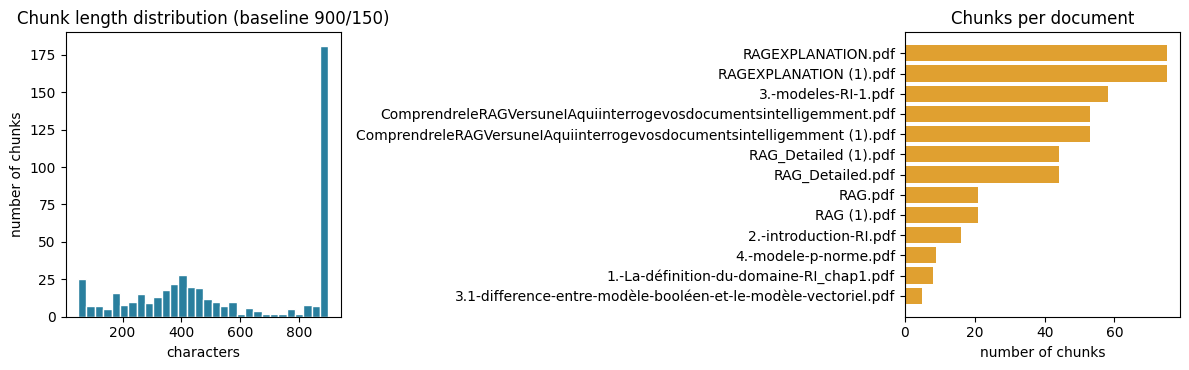

In [12]:
rows = []
for size, ov in [(600, 100), (900, 150), (1200, 200)]:
    ch = chunk_pages(pages, size, ov)
    lengths = np.array([len(c["text"]) for c in ch])
    rows.append({"chunk_size": size, "overlap": ov, "n_chunks": len(ch),
                 "mean_length": round(lengths.mean(), 1), "median_length": float(np.median(lengths)),
                 "max_length": int(lengths.max())})
chunk_compare_df = pd.DataFrame(rows)
display(chunk_compare_df)

lengths = [len(c["text"]) for c in baseline_chunks]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(lengths, bins=30, color="#2a7f9e", edgecolor="white")
ax[0].set_title(f"Chunk length distribution (baseline {CHUNK_SIZE}/{CHUNK_OVERLAP})")
ax[0].set_xlabel("characters"); ax[0].set_ylabel("number of chunks")
per_doc = pd.Series([c["source"] for c in baseline_chunks]).value_counts()
ax[1].barh(per_doc.index[::-1], per_doc.values[::-1], color="#e0a030")
ax[1].set_title("Chunks per document"); ax[1].set_xlabel("number of chunks")
plt.tight_layout(); plt.show()

> **Interpretation.** If your pages are short (e.g. slide decks), most pages produce a *single* chunk whatever the chunk size, so the three configurations will look similar. Differences appear on long, dense pages. Chunking is applied page by page, so a passage that spans two pages is never merged into one chunk.

## STEP 6 — Embedding generation

An **embedding** maps a text to a dense vector $\mathbf{x}\in\mathbb{R}^d$ such that texts with related meaning are close in the vector space. This makes *semantic* search possible: a question and a passage can match even when they share few words (and, with a multilingual model, even across languages).

We use `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2` (baseline). Vectors are **L2-normalised**, $\|\mathbf{x}\|_2 = 1$, and stored as `float32` (FAISS requirement). Normalisation matters because the cosine similarity then reduces to a dot product (Step 7) and the score no longer depends on text length.

**Important limitation.** Sentence-Transformers models truncate inputs to a maximum sequence length (`model.max_seq_length`, 128 word-pieces for this model). Characters beyond that limit are **not embedded**. The cell below measures how many chunks exceed the limit so you can interpret chunk-size experiments correctly. We keep the course baseline model; consider a model with a longer limit if truncation is large.

In [13]:
def load_embedding_model(name=EMBEDDING_MODEL_NAME):
    print(f"Loading embedding model: {name} (device={DEVICE})")
    return SentenceTransformer(name, device=DEVICE)


def embed_texts(model, texts, batch_size=32, show_progress_bar=True):
    # Encode texts into L2-normalised float32 vectors.
    if not texts:
        raise ValueError("No text to embed.")
    vectors = model.encode(texts, batch_size=batch_size, convert_to_numpy=True,
                           normalize_embeddings=True, show_progress_bar=show_progress_bar)
    vectors = np.ascontiguousarray(vectors.astype("float32"))
    assert np.allclose(np.linalg.norm(vectors, axis=1), 1.0, atol=1e-3), "embeddings are not normalised"
    return vectors


def truncation_report(model, texts):
    # Share of texts longer than the embedding model's maximum sequence length.
    max_len = model.max_seq_length
    n_tokens = np.array([len(model.tokenizer(t, add_special_tokens=True)["input_ids"]) for t in texts])
    return {"max_seq_length": max_len, "mean_tokens": float(n_tokens.mean()),
            "max_tokens": int(n_tokens.max()), "pct_truncated": float(100 * (n_tokens > max_len).mean())}


embedding_model = load_embedding_model()
print("Embedding dimension:", embedding_model.get_sentence_embedding_dimension())
print("Truncation check on baseline chunks:", truncation_report(embedding_model, [c["text"] for c in baseline_chunks]))

Loading embedding model: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2 (device=cuda)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (199 > 128). Running this sequence through the model will result in indexing errors


Embedding dimension: 384
Truncation check on baseline chunks: {'max_seq_length': 128, 'mean_tokens': 146.17634854771785, 'max_tokens': 300, 'pct_truncated': 54.56431535269709}


In [14]:
baseline_texts = [c["text"] for c in baseline_chunks]
t0 = time.perf_counter()
baseline_embeddings = embed_texts(embedding_model, baseline_texts, show_progress_bar=True)
print(f"\nEmbedding shape : {baseline_embeddings.shape}  (chunks x dimensions), dtype={baseline_embeddings.dtype}")
print(f"Chunks to index : {len(baseline_chunks)}")
print(f"Encoding time   : {time.perf_counter() - t0:.1f} s")
print("Norm of first vector:", float(np.linalg.norm(baseline_embeddings[0])))

Batches:   0%|          | 0/16 [00:00<?, ?it/s]


Embedding shape : (482, 384)  (chunks x dimensions), dtype=float32
Chunks to index : 482
Encoding time   : 1.6 s
Norm of first vector: 0.9999999403953552


### Visualising the embedding space

A 2-D PCA projection (computed with NumPy's SVD) shows whether chunks from different documents/topics form groups. It is a *qualitative* illustration only: two dimensions cannot represent a 384-dimensional space faithfully.

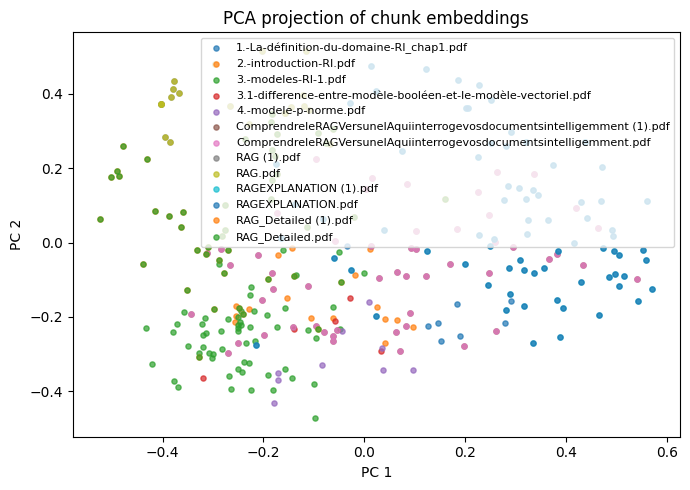

In [15]:
def pca_2d(vectors):
    centered = vectors - vectors.mean(axis=0, keepdims=True)
    _, _, vt = np.linalg.svd(centered, full_matrices=False)
    return centered @ vt[:2].T


if len(baseline_embeddings) >= 3:
    idx = np.random.RandomState(SEED).choice(len(baseline_embeddings), size=min(3000, len(baseline_embeddings)), replace=False)
    proj = pca_2d(baseline_embeddings[idx])
    sources = np.array([baseline_chunks[i]["source"] for i in idx])
    plt.figure(figsize=(7, 5))
    for s in sorted(set(sources)):
        m = sources == s
        plt.scatter(proj[m, 0], proj[m, 1], s=14, alpha=0.7, label=s)
    plt.title("PCA projection of chunk embeddings"); plt.xlabel("PC 1"); plt.ylabel("PC 2")
    plt.legend(fontsize=8, loc="best"); plt.tight_layout(); plt.show()
else:
    print("Not enough chunks for a projection.")

## STEP 7 — FAISS vector index

**FAISS** performs fast similarity search over vectors. `IndexFlatIP` is an *exact* (brute-force) index using the **inner product**:

$$\text{score}(\mathbf{q},\mathbf{x}) = \mathbf{q}\cdot\mathbf{x} = \|\mathbf{q}\|\,\|\mathbf{x}\|\cos\theta$$

When both vectors are L2-normalised ($\|\mathbf{q}\|=\|\mathbf{x}\|=1$) this equals $\cos\theta$, i.e. **cosine similarity** (range $[-1,1]$, higher = more similar).
Exact search is ideal for small/medium collections; for millions of vectors approximate indexes (IVF, HNSW, PQ) trade accuracy for speed and memory.

**Critical invariant:** FAISS only stores vectors; the text and metadata live in a separate list. The $i$-th vector must correspond to the $i$-th metadata entry. We store everything in a `KnowledgeBase` object, save the index to `rag_index.faiss`, the metadata to `chunks.json`, the settings to `index_config.json`, and validate their consistency on every build/load.

In [16]:
@dataclass
class KnowledgeBase:
    index: "faiss.Index"
    chunks: List[dict]
    embedding_model_name: str
    chunk_size: int
    overlap: int


def build_faiss_index(vectors):
    index = faiss.IndexFlatIP(vectors.shape[1])
    index.add(vectors)
    return index


def validate_knowledge_base(kb, raise_on_error=True):
    # Detect index/metadata mismatches. Returns the list of problems found.
    problems = []
    if kb.index.ntotal != len(kb.chunks):
        problems.append(f"index has {kb.index.ntotal} vectors but metadata has {len(kb.chunks)} chunks")
    required = {"text", "source", "page", "chunk_id", "uid"}
    for i, c in enumerate(kb.chunks):
        if not required.issubset(c):
            problems.append(f"metadata entry {i} misses fields {sorted(required - set(c))}")
            break
    if len({c.get("uid") for c in kb.chunks}) != len(kb.chunks):
        problems.append("chunk uids are not unique")
    if problems and raise_on_error:
        raise ValueError("Knowledge-base validation failed: " + "; ".join(problems)
                         + ". Rebuild index and metadata together.")
    return problems


def build_knowledge_base(page_list, chunk_size, overlap, model, show_progress=True):
    chunks = chunk_pages(page_list, chunk_size, overlap)
    if not chunks:
        raise ValueError("No chunks were produced.")
    vectors = embed_texts(model, [c["text"] for c in chunks], show_progress_bar=show_progress)
    kb = KnowledgeBase(build_faiss_index(vectors), chunks, EMBEDDING_MODEL_NAME, chunk_size, overlap)
    validate_knowledge_base(kb)
    return kb


def save_knowledge_base(kb, directory=ARTIFACT_DIR):
    directory = Path(directory); directory.mkdir(parents=True, exist_ok=True)
    validate_knowledge_base(kb)
    faiss.write_index(kb.index, str(directory / "rag_index.faiss"))
    with open(directory / "chunks.json", "w", encoding="utf-8") as f:
        json.dump(kb.chunks, f, ensure_ascii=False, indent=2)
    with open(directory / "index_config.json", "w", encoding="utf-8") as f:
        json.dump({"embedding_model": kb.embedding_model_name, "chunk_size": kb.chunk_size,
                   "overlap": kb.overlap, "n_vectors": kb.index.ntotal, "dimension": kb.index.d}, f, indent=2)
    print(f"Saved index + metadata to {directory.resolve()}")


def load_knowledge_base(directory=ARTIFACT_DIR):
    directory = Path(directory)
    index = faiss.read_index(str(directory / "rag_index.faiss"))
    with open(directory / "chunks.json", encoding="utf-8") as f:
        chunks = json.load(f)
    with open(directory / "index_config.json", encoding="utf-8") as f:
        cfg = json.load(f)
    if cfg["embedding_model"] != EMBEDDING_MODEL_NAME:
        raise ValueError(f"Index was built with '{cfg['embedding_model']}', not '{EMBEDDING_MODEL_NAME}'. "
                         "Queries must use the same embedding model as the documents.")
    kb = KnowledgeBase(index, chunks, cfg["embedding_model"], cfg["chunk_size"], cfg["overlap"])
    validate_knowledge_base(kb)
    return kb

In [17]:
ACTIVE_KB = KnowledgeBase(build_faiss_index(baseline_embeddings), baseline_chunks,
                          EMBEDDING_MODEL_NAME, CHUNK_SIZE, CHUNK_OVERLAP)
validate_knowledge_base(ACTIVE_KB)
print("Number of indexed vectors:", ACTIVE_KB.index.ntotal, "| dimension:", ACTIVE_KB.index.d)

# Save, reload and verify the round trip
save_knowledge_base(ACTIVE_KB)
reloaded_kb = load_knowledge_base()
q = embed_texts(embedding_model, ["test query about chunking"], show_progress_bar=False)
s1, p1 = ACTIVE_KB.index.search(q, min(3, ACTIVE_KB.index.ntotal))
s2, p2 = reloaded_kb.index.search(q, min(3, reloaded_kb.index.ntotal))
assert (p1 == p2).all() and np.allclose(s1, s2), "reloaded index returns different results"
print("Round-trip check passed: reloaded index returns identical results.")

# Demonstrate the mismatch detector on a deliberately broken copy
broken = KnowledgeBase(ACTIVE_KB.index, ACTIVE_KB.chunks[:-1], EMBEDDING_MODEL_NAME, CHUNK_SIZE, CHUNK_OVERLAP)
print("Mismatch detector ->", validate_knowledge_base(broken, raise_on_error=False))

Number of indexed vectors: 482 | dimension: 384
Saved index + metadata to /content/artifacts
Round-trip check passed: reloaded index returns identical results.
Mismatch detector -> ['index has 482 vectors but metadata has 481 chunks']


## STEP 8 — Semantic retrieval

`retrieve(question, top_k)` encodes the question with the **same** embedding model (and normalisation), searches the index and maps the returned vector positions back to chunk metadata. FAISS returns `-1` when fewer than `top_k` vectors exist; those entries are skipped.

`top_k` controls the recall/noise trade-off: a larger value is more likely to contain the needed evidence but adds irrelevant context and generation cost. **A high similarity score does not prove relevance**, so we always inspect retrieved passages *before* generation.

In [18]:
def retrieve(question, top_k=TOP_K, kb=None, model=None):
    kb = ACTIVE_KB if kb is None else kb
    model = embedding_model if model is None else model
    if not isinstance(question, str) or not question.strip():
        raise ValueError("The question must be a non-empty string.")
    top_k = int(top_k)
    if top_k < 1:
        raise ValueError("top_k must be >= 1")
    top_k = min(top_k, kb.index.ntotal)
    query_vector = model.encode([question.strip()], convert_to_numpy=True,
                                normalize_embeddings=True).astype("float32")
    scores, positions = kb.index.search(query_vector, top_k)
    results = []
    for rank, (score, pos) in enumerate(zip(scores[0], positions[0]), start=1):
        if pos == -1:
            continue
        item = dict(kb.chunks[pos])
        item["score"] = float(score)
        item["rank"] = rank
        results.append(item)
    return results


def show_retrieved(results, max_chars=450):
    for r in results:
        print(f"[{r['rank']}] {r['source']} | page {r['page']} | chunk {r['chunk_id']} | similarity = {r['score']:.3f}")
        snippet = r["text"].replace("\n", " ")
        print("    " + (snippet[:max_chars] + (" ..." if len(snippet) > max_chars else "")))
        print()

Question: What chunk size and overlap does the guide recommend as starting values? 

[1] RAG_Detailed.pdf | page 40 | chunk 0 | similarity = 0.628
    Example experiment matrix Baseline: chunk size 900, overlap 150, top_k 4. Variant A: chunk size 600, overlap 100, top_k 4. Variant B: chunk size 900, overlap 150, top_k 6. Variant C: chunk size 1200, overlap 200, top_k 4. Measure Precision@k, Recall@k, answer quality, latency, and memory for every configuration. Use the same evaluation questions for a fair comparison. Practical Guide to RAG • 40

[2] RAG_Detailed (1).pdf | page 40 | chunk 0 | similarity = 0.628
    Example experiment matrix Baseline: chunk size 900, overlap 150, top_k 4. Variant A: chunk size 600, overlap 100, top_k 4. Variant B: chunk size 900, overlap 150, top_k 6. Variant C: chunk size 1200, overlap 200, top_k 4. Measure Precision@k, Recall@k, answer quality, latency, and memory for every configuration. Use the same evaluation questions for a fair comparison. Practica

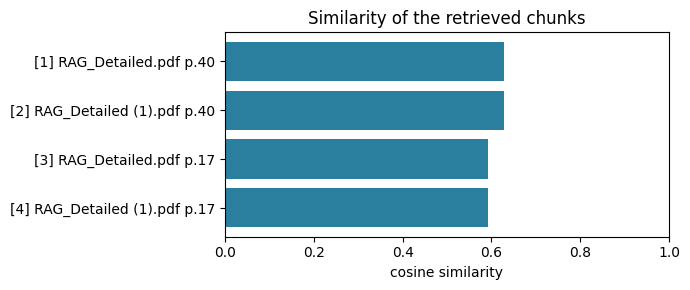

In [19]:
sample_question = DEMO_QUESTIONS[0]
print("Question:", sample_question, "\n")
sample_results = retrieve(sample_question, top_k=TOP_K)
show_retrieved(sample_results)

plt.figure(figsize=(7, 3))
labels = [f"[{r['rank']}] {r['source']} p.{r['page']}" for r in sample_results]
plt.barh(labels[::-1], [r["score"] for r in sample_results][::-1], color="#2a7f9e")
plt.xlabel("cosine similarity"); plt.title("Similarity of the retrieved chunks"); plt.xlim(0, 1)
plt.tight_layout(); plt.show()

## STEP 9 — Hugging Face language model (generation)

The primary generator is **`Qwen/Qwen2.5-3B-Instruct`** (course baseline), loaded with `AutoTokenizer` and `AutoModelForCausalLM`.

**Resource-aware loading.** A 3B-parameter model needs roughly *2 bytes × 3·10⁹ ≈ 6–7 GB* in 16-bit precision plus activation memory: it fits on a free Colab T4 GPU (15 GB) but is very slow on CPU. The loader:

1. estimates the memory requirement and prints the available GPU/CPU memory;
2. uses `bfloat16` when supported, otherwise `float16` on GPU (`bfloat16` on CPU);
3. if – and only if – loading fails with an out-of-memory error and `ALLOW_FALLBACK=True`, switches to **`Qwen/Qwen2.5-1.5B-Instruct`** and prints a prominent warning. The model actually used is stored in `ACTIVE_GENERATION_MODEL` and must be reported with any result. Set `ALLOW_FALLBACK=False` to forbid the switch.

**Authentication.** Qwen2.5 models are public, so no token is required. If you later choose a gated model, store the token in Colab *Secrets* (key icon in the left sidebar) under the name `HF_TOKEN` and enable notebook access; **never paste a token into a cell or commit it to GitHub**.

In [20]:
def configure_hf_token():
    # Optional: log in to Hugging Face using a token stored in Colab Secrets or an environment variable.
    token = None
    try:
        from google.colab import userdata
        token = userdata.get("HF_TOKEN")
    except Exception:
        token = os.environ.get("HF_TOKEN")
    if token:
        from huggingface_hub import login
        login(token=token, add_to_git_credential=False)
        print("Hugging Face token configured (value not displayed).")
    else:
        print("No HF_TOKEN found - fine for public models such as Qwen2.5-3B-Instruct.")


configure_hf_token()

No HF_TOKEN found - fine for public models such as Qwen2.5-3B-Instruct.


In [21]:
tokenizer, gen_model, ACTIVE_GENERATION_MODEL = None, None, None


def estimate_requirements_gb(model_name):
    m = re.search(r"(\d+(?:\.\d+)?)B", model_name)
    return float(m.group(1)) * 2 if m else None           # ~2 bytes per parameter in 16-bit precision


def available_memory_gb():
    if torch.cuda.is_available():
        free, _total = torch.cuda.mem_get_info()
        return free / 1e9, "GPU memory"
    try:
        import psutil
        return psutil.virtual_memory().available / 1e9, "system RAM"
    except ImportError:
        return None, "system RAM"


def _is_oom(exc):
    return isinstance(exc, MemoryError) or "out of memory" in str(exc).lower() or exc.__class__.__name__ == "OutOfMemoryError"


def _load_causal_lm(model_name):
    tok = AutoTokenizer.from_pretrained(model_name)
    if torch.cuda.is_available():
        dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
        kwargs = {"device_map": "auto"}
    else:
        dtype, kwargs = torch.bfloat16, {}
    try:
        mdl = AutoModelForCausalLM.from_pretrained(model_name, dtype=dtype, **kwargs)
    except (TypeError, ValueError):                       # older transformers versions use torch_dtype
        mdl = AutoModelForCausalLM.from_pretrained(model_name, torch_dtype=dtype, **kwargs)
    mdl.eval()
    return tok, mdl


def load_generation_model(model_name=GENERATION_MODEL_NAME, fallback_name=FALLBACK_GENERATION_MODEL_NAME,
                          allow_fallback=ALLOW_FALLBACK):
    need = estimate_requirements_gb(model_name)
    avail, where = available_memory_gb()
    print(f"Loading '{model_name}' | estimated weights ~{need} GB | available {where}: "
          + (f"{avail:.1f} GB" if avail else "unknown"))
    if not torch.cuda.is_available():
        print("WARNING: no GPU detected - generation on CPU will be slow.")
    try:
        tok, mdl = _load_causal_lm(model_name)
        return tok, mdl, model_name
    except Exception as exc:
        if not (_is_oom(exc) and allow_fallback and fallback_name):
            raise
        print("\n" + "!" * 78)
        print(f"!! '{model_name}' does not fit in memory ({exc.__class__.__name__}).")
        print(f"!! SWITCHING TO FALLBACK MODEL '{fallback_name}'. Results are NOT from the course baseline model.")
        print("!" * 78 + "\n")
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        tok, mdl = _load_causal_lm(fallback_name)
        return tok, mdl, fallback_name


tokenizer, gen_model, ACTIVE_GENERATION_MODEL = load_generation_model()
print("\nActive generation model:", ACTIVE_GENERATION_MODEL, "| device:", gen_model.device)

Loading 'Qwen/Qwen2.5-3B-Instruct' | estimated weights ~6.0 GB | available GPU memory: 14.9 GB


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]


Active generation model: Qwen/Qwen2.5-3B-Instruct | device: cuda:0


## STEP 10 — RAG prompt engineering

The system prompt turns the LLM from a free-form generator into a *reader of supplied evidence*. It instructs the model to

* use **only** the numbered passages, with no outside knowledge or guessing;
* answer with a fixed sentence when the passages are insufficient (this makes abstentions easy to detect and test);
* cite passage numbers like `[1]` and never invent file names, page numbers or source numbers;
* separate explicit evidence from inference and flag uncertainty;
* answer in the language of the question.

The context is formatted as `[i] Source: <file>, page <n>` followed by the passage text. We use the tokenizer's **chat template** and decode **only the newly generated tokens** (the prompt is excluded). Greedy decoding (`do_sample=False`) makes the output reproducible for a given model and prompt.

> A prompt *encourages* grounded behaviour; it cannot *guarantee* it. Small models can still ignore instructions, so the pipeline also performs automatic citation checks and Step 15 evaluates grounding with a human rubric.

In [22]:
ABSTAIN_MESSAGE = "The provided documents do not contain enough information to answer this question."

SYSTEM_PROMPT = (
    "You are a careful document assistant. Answer the user's question using ONLY the numbered context "
    "passages provided. Rules:\n"
    "1. Do not use outside knowledge and do not guess.\n"
    f"2. If the passages do not contain enough information, reply with: \"{ABSTAIN_MESSAGE}\" "
    "and briefly say what is missing.\n"
    "3. Support each statement with the source numbers of the passages, written like [1] or [2][3].\n"
    "4. Never invent document names, page numbers or source numbers.\n"
    "5. Distinguish what the passages state explicitly from inferences; mark inferences as such and mention "
    "uncertainty when the evidence is partial or contradictory.\n"
    "6. Answer in the same language as the question and be concise."
)


def build_messages(question, retrieved):
    context = "\n\n".join(f"[{r['rank']}] Source: {r['source']}, page {r['page']}\n{r['text']}" for r in retrieved)
    return [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f"Context:\n{context}\n\nQuestion: {question}"},
    ]


def generate_answer(question, retrieved, max_new_tokens=MAX_NEW_TOKENS):
    if gen_model is None or tokenizer is None:
        raise RuntimeError("The generation model is not loaded. Run the Step 9 cell first.")
    prompt = tokenizer.apply_chat_template(build_messages(question, retrieved), tokenize=False,
                                           add_generation_prompt=True)
    inputs = tokenizer(prompt, return_tensors="pt").to(gen_model.device)
    n_prompt_tokens = inputs["input_ids"].shape[1]
    with torch.inference_mode():
        output = gen_model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    new_tokens = output[0][n_prompt_tokens:]                 # drop the prompt, keep only the answer
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip()


def check_citations(answer, retrieved):
    # Flag citations to non-existent sources and page numbers that were not retrieved.
    n = len(retrieved)
    cited = sorted({int(m) for m in re.findall(r"\[(\d+)\]", answer)})
    invalid_sources = [c for c in cited if c < 1 or c > n]
    retrieved_pages = {r["page"] for r in retrieved}
    mentioned_pages = sorted({int(m) for m in re.findall(r"\bpages?\s+(\d+)", answer, flags=re.I)})
    unsupported_pages = [p for p in mentioned_pages if p not in retrieved_pages]
    return {"cited_sources": cited, "has_citation": bool(cited), "invalid_sources": invalid_sources,
            "unsupported_pages": unsupported_pages}


def is_abstention(answer):
    a = answer.lower()
    return any(s in a for s in ["do not contain enough information", "does not contain enough information",
                                "not enough information", "cannot be answered", "no information"])


print(SYSTEM_PROMPT)

You are a careful document assistant. Answer the user's question using ONLY the numbered context passages provided. Rules:
1. Do not use outside knowledge and do not guess.
2. If the passages do not contain enough information, reply with: "The provided documents do not contain enough information to answer this question." and briefly say what is missing.
3. Support each statement with the source numbers of the passages, written like [1] or [2][3].
4. Never invent document names, page numbers or source numbers.
5. Distinguish what the passages state explicitly from inferences; mark inferences as such and mention uncertainty when the evidence is partial or contradictory.
6. Answer in the same language as the question and be concise.


## STEP 11 — Complete question-answering pipeline

`ask_question(question, top_k)` runs: **retrieve → build context → generate → verify citations → return answer + sources**, and prints the retrieved evidence so that a reader can verify the answer against the original PDF page.

If `min_score` is set and the best retrieval score is below it, the function abstains *without calling the LLM*, which is cheaper and safer for clearly out-of-scope questions.

In [23]:
def ask_question(question, top_k=TOP_K, min_score=MIN_SIMILARITY, show=True, kb=None, max_new_tokens=MAX_NEW_TOKENS):
    t0 = time.perf_counter()
    retrieved = retrieve(question, top_k, kb=kb)
    t_retrieval = time.perf_counter() - t0

    skipped = min_score is not None and (not retrieved or retrieved[0]["score"] < min_score)
    t1 = time.perf_counter()
    answer = ABSTAIN_MESSAGE if skipped else generate_answer(question, retrieved, max_new_tokens)
    t_generation = time.perf_counter() - t1

    result = {
        "question": question,
        "answer": answer,
        "sources": [{"rank": r["rank"], "source": r["source"], "page": r["page"],
                     "chunk_id": r["chunk_id"], "score": r["score"]} for r in retrieved],
        "retrieved": retrieved,
        "citation_check": check_citations(answer, retrieved),
        "abstained": is_abstention(answer),
        "generation_skipped_low_similarity": skipped,
        "retrieval_seconds": t_retrieval,
        "generation_seconds": t_generation,
        "generation_model": ACTIVE_GENERATION_MODEL,
    }
    if show:
        display_result(result)
    return result


def display_result(result, max_chars=350):
    print("=" * 100)
    print("QUESTION:", result["question"])
    print("-" * 100)
    print("ANSWER:\n" + result["answer"])
    cc = result["citation_check"]
    print("\nCitation check: cited sources =", cc["cited_sources"] or "none",
          "| invalid source numbers =", cc["invalid_sources"] or "none",
          "| page numbers not in retrieved passages =", cc["unsupported_pages"] or "none")
    print(f"Timing: retrieval {result['retrieval_seconds'] * 1000:.0f} ms, generation {result['generation_seconds']:.1f} s "
          f"({result['generation_model']})")
    print("-" * 100 + "\nRETRIEVED EVIDENCE:")
    show_retrieved(result["retrieved"], max_chars=max_chars)

### Demonstration: five answerable and two unanswerable questions

The last two questions are **not** answered by the guide: a grounded system should abstain. Read each answer against the retrieved evidence and the original PDF page; the automatic checks only detect formal problems (invalid source numbers, unretrieved page numbers).

In [24]:
demo_results = []
for q in DEMO_QUESTIONS:
    demo_results.append(ask_question(q, top_k=TOP_K))

QUESTION: What chunk size and overlap does the guide recommend as starting values?
----------------------------------------------------------------------------------------------------
ANSWER:
The guide recommends a chunk size of 900 characters and an overlap of 150 characters as starting values [3][4].

Citation check: cited sources = [3, 4] | invalid source numbers = none | page numbers not in retrieved passages = none
Timing: retrieval 17 ms, generation 3.3 s (Qwen/Qwen2.5-3B-Instruct)
----------------------------------------------------------------------------------------------------
RETRIEVED EVIDENCE:
[1] RAG_Detailed.pdf | page 40 | chunk 0 | similarity = 0.628
    Example experiment matrix Baseline: chunk size 900, overlap 150, top_k 4. Variant A: chunk size 600, overlap 100, top_k 4. Variant B: chunk size 900, overlap 150, top_k 6. Variant C: chunk size 1200, overlap 200, top_k 4. Measure Precision@k, Recall@k, answer quality, latency, and memory for every configuration. Use th

In [25]:
summary = pd.DataFrame([{
    "question": r["question"][:70],
    "abstained": r["abstained"],
    "has_citation": r["citation_check"]["has_citation"],
    "invalid_sources": r["citation_check"]["invalid_sources"],
    "top1_score": round(r["sources"][0]["score"], 3),
    "generation_s": round(r["generation_seconds"], 1),
} for r in demo_results])
display(summary)

,question,abstained,has_citation,invalid_sources,top1_score,generation_s
0,What chunk size and overlap does the guide rec...,False,True,[],0.628,3.3
1,"What does IndexFlatIP compute, and why does it...",False,True,[],0.642,3.6
2,How is Mean Reciprocal Rank (MRR) calculated?,False,True,[],0.854,8.2
3,Which language model does the guide use for ge...,False,True,[],0.636,3.6
4,What should I do if the text extracted from a ...,False,True,[],0.637,5.6
5,What is the capital city of Australia?,True,False,[],0.228,2.6
6,What accuracy did the guide report for Qwen2.5...,True,False,[],0.493,2.2


## STEP 12 — Interactive interface (Gradio)

The interface calls the **same** `ask_question` pipeline defined above (no separate mock). It exposes the question box, an adjustable Top-K slider, the generated answer, and a table with the retrieved sources, page numbers, similarity scores and passage previews.
In Colab, the app appears inline and also provides a temporary public link only if you set `share=True`.

In [26]:
import gradio as gr


def gradio_ask(question, top_k):
    if not question or not question.strip():
        return "Please type a question.", pd.DataFrame()
    try:
        res = ask_question(question, top_k=int(top_k), show=False)
    except Exception as exc:
        return f"**Error:** {exc}", pd.DataFrame()
    cc = res["citation_check"]
    notes = []
    if cc["invalid_sources"]:
        notes.append(f"citations to non-existent sources: {cc['invalid_sources']}")
    if cc["unsupported_pages"]:
        notes.append(f"page numbers not found in the retrieved passages: {cc['unsupported_pages']}")
    footer = "\n\n---\n*Automatic check: " + ("; ".join(notes) if notes else "no formal citation problem detected") + \
             ". Always verify against the original PDF page.*"
    table = pd.DataFrame([{"Source #": r["rank"], "Document": r["source"], "Page": r["page"],
                           "Similarity": round(r["score"], 3),
                           "Passage": r["text"][:500] + (" ..." if len(r["text"]) > 500 else "")}
                          for r in res["retrieved"]])
    return res["answer"] + footer, table


with gr.Blocks(title="Intelligent Document Assistant (RAG)") as demo:
    gr.Markdown("# Intelligent Document Assistant\nAsk a question about your uploaded PDFs. "
                "Answers are grounded in retrieved passages; verify them against the cited pages.")
    with gr.Row():
        with gr.Column(scale=2):
            question_box = gr.Textbox(label="Your question", lines=3, placeholder="e.g. What chunk size does the guide use?")
            topk_slider = gr.Slider(1, 10, value=TOP_K, step=1, label="Top-K retrieved passages")
            ask_button = gr.Button("Ask", variant="primary")
        with gr.Column(scale=3):
            gr.Markdown("### Answer")
            answer_box = gr.Markdown()
    sources_table = gr.Dataframe(headers=["Source #", "Document", "Page", "Similarity", "Passage"],
                                 wrap=True, label="Retrieved sources")
    ask_button.click(gradio_ask, [question_box, topk_slider], [answer_box, sources_table])
    question_box.submit(gradio_ask, [question_box, topk_slider], [answer_box, sources_table])

demo.launch(share=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

## STEP 13 — Evaluation dataset

A RAG system must be evaluated on a **fixed set of questions** with known relevant evidence. Each entry contains: the question, a reference answer, the relevant *source* and *pages*, and whether the question is answerable at all. Unanswerable questions have no relevant pages; they test abstention.

**Labelling policy used here.**
* Relevance is labelled at **page level** `(source, page)` rather than by chunk id, because chunk ids change whenever the chunk size changes; page labels let us compare chunking configurations fairly. The helper below lists which chunk ids of the *current* index lie on the labelled pages (`relevant_chunk_ids`).
* The labels and reference answers below were written for the course guide **`RAG_Detailed.pdf`** by reading its pages. **You must check them manually against the actual uploaded PDF** (page numbers are physical PDF pages). If you index other documents, replace the dataset with your own questions; questions whose labelled pages are not found in the uploaded files are automatically excluded and reported.
* No scores are pre-filled anywhere.

In [27]:
def pg(source, *page_numbers):
    return [{"source": source, "page": p} for p in page_numbers]


GUIDE = "RAG_Detailed.pdf"

EVAL_SET = [
    {"id": "Q1", "answerable": True,
     "question": "What chunk size and overlap does the guide use as starting values?",
     "reference_answer": "900 characters with 150 characters of overlap, presented as starting values and not universal best settings.",
     "relevant_pages": pg(GUIDE, 17, 18, 19)},
    {"id": "Q2", "answerable": True,
     "question": "Which FAISS index type performs exact search and which similarity does it use?",
     "reference_answer": "IndexFlatIP performs exact search using inner-product similarity; with normalized embeddings this corresponds to cosine similarity.",
     "relevant_pages": pg(GUIDE, 23)},
    {"id": "Q3", "answerable": True,
     "question": "How is Mean Reciprocal Rank computed?",
     "reference_answer": "Reciprocal rank is 1 divided by the rank of the first relevant result (0 if none is retrieved); MRR is the average over all evaluation questions.",
     "relevant_pages": pg(GUIDE, 36, 37)},
    {"id": "Q4", "answerable": True,
     "question": "How are Precision@k and Recall@k defined?",
     "reference_answer": "Precision@k is the number of relevant passages among the top k divided by k; Recall@k is the number of relevant passages found in the top k divided by all known relevant passages.",
     "relevant_pages": pg(GUIDE, 35, 37)},
    {"id": "Q5", "answerable": True,
     "question": "Which generation model does the guide demonstrate?",
     "reference_answer": "Qwen/Qwen2.5-3B-Instruct, loaded through Hugging Face Transformers.",
     "relevant_pages": pg(GUIDE, 28, 29)},
    {"id": "Q6", "answerable": True,
     "question": "What should be done when the text extracted from a PDF is empty?",
     "reference_answer": "Check whether the PDF is scanned; scanned PDFs contain images instead of selectable text, so OCR may be needed.",
     "relevant_pages": pg(GUIDE, 15, 41)},
    {"id": "Q7", "answerable": True,
     "question": "Why must chunks.json keep the same order as the vectors added to FAISS?",
     "reference_answer": "Because the vector positions returned by FAISS are used to select the matching chunk text and metadata; if the order differs the index and metadata are mismatched and both must be rebuilt together.",
     "relevant_pages": pg(GUIDE, 8, 24, 25, 41)},
    {"id": "Q8", "answerable": True,
     "question": "What privacy and licensing points should be checked when using a RAG system?",
     "reference_answer": "Check where documents and questions are processed (local versus hosted models) and review the license terms of the model, the embedding model and the libraries.",
     "relevant_pages": pg(GUIDE, 33, 42)},
    {"id": "U1", "answerable": False,
     "question": "What is the capital city of Australia?",
     "reference_answer": "Not answerable from the documents: the system should abstain.",
     "relevant_pages": []},
    {"id": "U2", "answerable": False,
     "question": "What accuracy did the guide report for Qwen2.5-3B-Instruct on the MMLU benchmark?",
     "reference_answer": "Not answerable from the documents: the guide reports no benchmark accuracy.",
     "relevant_pages": []},
    {"id": "U3", "answerable": False,
     "question": "Who is the author of the guide and which university published it?",
     "reference_answer": "Not answerable from the documents: no author or institution is stated in the guide.",
     "relevant_pages": []},
]

# ---- validate the labels against the documents that were actually uploaded ----
available_pages = {(p["source"], p["page"]) for p in pages}
labeled_eval, unanswerable_eval, excluded = [], [], []
for q in EVAL_SET:
    if not q["answerable"]:
        unanswerable_eval.append(q)
        continue
    missing = [rp for rp in q["relevant_pages"] if (rp["source"], rp["page"]) not in available_pages]
    if missing:
        excluded.append((q["id"], missing))
    else:
        labeled_eval.append(q)

print(f"Answerable questions usable for retrieval evaluation: {len(labeled_eval)}")
print(f"Unanswerable (abstention) questions                  : {len(unanswerable_eval)}")
if excluded:
    print("\nExcluded (labelled pages not found in the uploaded PDFs - upload the matching file or edit the labels):")
    for qid, miss in excluded:
        print("  ", qid, "->", [(m['source'], m['page']) for m in miss])


def chunk_ids_for_pages(kb, relevant_pages):
    wanted = {(rp["source"], rp["page"]) for rp in relevant_pages}
    return [c["uid"] for c in kb.chunks if (c["source"], c["page"]) in wanted]


eval_table = pd.DataFrame([{
    "id": q["id"], "answerable": q["answerable"], "question": q["question"],
    "relevant_pages": sorted({(rp["source"], rp["page"]) for rp in q["relevant_pages"]}),
    "n_relevant_chunks_in_current_index": len(chunk_ids_for_pages(ACTIVE_KB, q["relevant_pages"])),
} for q in EVAL_SET])
display(eval_table)

for q in EVAL_SET:
    q["relevant_chunk_ids_baseline"] = chunk_ids_for_pages(ACTIVE_KB, q["relevant_pages"])
with open(ARTIFACT_DIR / "eval_questions.json", "w", encoding="utf-8") as f:
    json.dump(EVAL_SET, f, ensure_ascii=False, indent=2)
print("\nEvaluation set saved to", ARTIFACT_DIR / "eval_questions.json")

Answerable questions usable for retrieval evaluation: 8
Unanswerable (abstention) questions                  : 3


,id,answerable,question,relevant_pages,n_relevant_chunks_in_current_index
0,Q1,True,What chunk size and overlap does the guide use...,"[(RAG_Detailed.pdf, 17), (RAG_Detailed.pdf, 18...",3
1,Q2,True,Which FAISS index type performs exact search a...,"[(RAG_Detailed.pdf, 23)]",1
2,Q3,True,How is Mean Reciprocal Rank computed?,"[(RAG_Detailed.pdf, 36), (RAG_Detailed.pdf, 37)]",2
3,Q4,True,How are Precision@k and Recall@k defined?,"[(RAG_Detailed.pdf, 35), (RAG_Detailed.pdf, 37)]",2
4,Q5,True,Which generation model does the guide demonstr...,"[(RAG_Detailed.pdf, 28), (RAG_Detailed.pdf, 29)]",2
5,Q6,True,What should be done when the text extracted fr...,"[(RAG_Detailed.pdf, 15), (RAG_Detailed.pdf, 41)]",2
6,Q7,True,Why must chunks.json keep the same order as th...,"[(RAG_Detailed.pdf, 8), (RAG_Detailed.pdf, 24)...",4
7,Q8,True,What privacy and licensing points should be ch...,"[(RAG_Detailed.pdf, 33), (RAG_Detailed.pdf, 42)]",2
8,U1,False,What is the capital city of Australia?,[],0
9,U2,False,What accuracy did the guide report for Qwen2.5...,[],0



Evaluation set saved to artifacts/eval_questions.json


## STEP 14 — Retrieval evaluation

For one question, let $R$ be the set of known relevant passages and $\text{top-}K$ the first $K$ retrieved items.

$$\text{Precision@}K=\frac{|\,\text{top-}K\cap R\,|}{K}\qquad
\text{Recall@}K=\frac{|\,\text{top-}K\cap R\,|}{|R|}\qquad
\text{RR}=\frac{1}{\text{rank of the first relevant item}}\ (0\ \text{if none})$$

$$\text{MRR}=\frac{1}{|Q|}\sum_{q\in Q}\text{RR}_q$$

**Implementation choices (page-level labels).** A retrieved *chunk* is relevant if its page is labelled relevant. Precision@K divides by $K$ (chunks). Recall@K counts **distinct relevant pages** found (so several chunks from one page cannot push recall above 1). RR uses the first relevant chunk.

**Edge cases.** If a question has no known relevant passage, Recall is *undefined* (`None`) and the question is excluded from retrieval averages; such questions are analysed separately through their similarity scores. If fewer than $K$ chunks exist, the denominator of Precision@K is still $K$.

In [28]:
def precision_at_k(retrieved_ids, relevant_ids, k):
    """Precision@K = (# relevant items among the top K) / K."""
    if k <= 0:
        raise ValueError("k must be positive")
    top_k = retrieved_ids[:k]
    return sum(x in relevant_ids for x in top_k) / k


def recall_at_k(retrieved_ids, relevant_ids, k):
    """Recall@K = (# relevant items found in the top K) / (# known relevant items).
    Returns None when the question has no known relevant item (recall is undefined)."""
    if not relevant_ids:
        return None
    top_k = retrieved_ids[:k]
    return sum(x in relevant_ids for x in set(top_k)) / len(relevant_ids)


def reciprocal_rank(retrieved_ids, relevant_ids):
    """RR = 1 / rank of the first relevant item (0 if none is retrieved)."""
    for rank, x in enumerate(retrieved_ids, start=1):
        if x in relevant_ids:
            return 1.0 / rank
    return 0.0


def evaluate_ranking(retrieved_page_keys, relevant_page_keys, k):
    """Page-level evaluation of one ranked list of chunks.

    retrieved_page_keys : [(source, page), ...] one entry per retrieved chunk, best first
    relevant_page_keys  : set of (source, page) labelled as relevant
    * Precision@K counts chunks whose page is relevant (denominator K).
    * Recall@K counts distinct relevant pages found (denominator = # relevant pages).
    * RR uses the rank of the first chunk lying on a relevant page.
    """
    relevant = set(relevant_page_keys)
    top = list(retrieved_page_keys[:k])
    unique_pages = list(dict.fromkeys(top))
    return {
        "precision": precision_at_k(top, relevant, k),
        "recall": recall_at_k(unique_pages, relevant, len(unique_pages)),
        "rr": reciprocal_rank(top, relevant),
    }

In [29]:
# ---- unit tests: reproduce the worked examples of the course presentation + edge cases ----
assert abs(precision_at_k(["a", "x", "b", "y", "c"], {"a", "b", "c", "d"}, 5) - 0.60) < 1e-9     # 3/5
assert abs(recall_at_k(["a", "x", "b", "y", "c"], {"a", "b", "c", "d"}, 5) - 0.75) < 1e-9        # 3/4
assert reciprocal_rank(["x", "a"], {"a"}) == 0.5
assert reciprocal_rank(["x", "y"], {"a"}) == 0.0
assert recall_at_k(["a"], set(), 1) is None                                                      # undefined
assert evaluate_ranking([("d", 1), ("d", 1), ("d", 2)], {("d", 1)}, 3)["recall"] == 1.0          # no recall > 1
print("Metric unit tests passed.")

Metric unit tests passed.


Per-question results at K = 4


,id,k,precision,recall,rr,n_relevant_pages
0,Q1,4,0.25,0.333333,0.333333,3
1,Q2,4,0.25,1.000000,1.000000,1
2,Q3,4,0.25,0.500000,1.000000,2
3,Q4,4,0.50,1.000000,1.000000,2
4,Q5,4,0.25,0.500000,0.500000,2
5,Q6,4,0.25,0.500000,0.333333,2
6,Q7,4,0.00,0.000000,0.000000,4
7,Q8,4,0.00,0.000000,0.000000,2


Mean over 8 labelled questions:


,Precision@K,Recall@K,MRR
k,,,
1,0.375,0.250,0.375
2,0.250,0.312,0.438
4,0.219,0.479,0.521
6,0.188,0.583,0.521


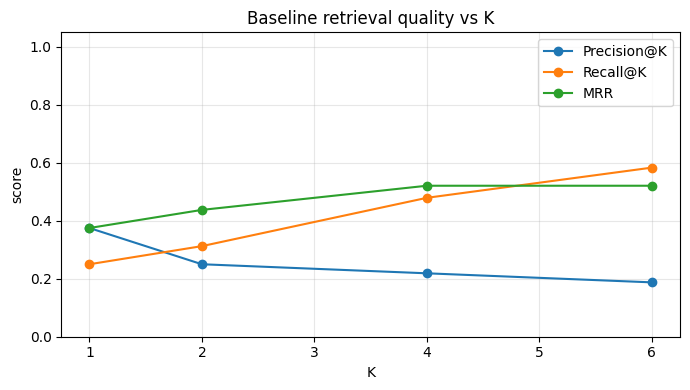

In [30]:
def evaluate_retrieval(kb, eval_questions, k_values, model=None):
    rows = []
    for q in eval_questions:
        results = retrieve(q["question"], max(k_values), kb=kb, model=model)
        keys = [(r["source"], r["page"]) for r in results]
        relevant = {(p["source"], p["page"]) for p in q["relevant_pages"]}
        for k in k_values:
            m = evaluate_ranking(keys, relevant, k)
            rows.append({"id": q["id"], "k": k, "precision": m["precision"], "recall": m["recall"], "rr": m["rr"],
                         "n_relevant_pages": len(relevant)})
    return pd.DataFrame(rows)


K_VALUES = [1, 2, 4, 6]
if labeled_eval:
    retrieval_df = evaluate_retrieval(ACTIVE_KB, labeled_eval, K_VALUES)
    print("Per-question results at K =", TOP_K)
    display(retrieval_df[retrieval_df.k == TOP_K].reset_index(drop=True))
    retrieval_summary = (retrieval_df.groupby("k")[["precision", "recall", "rr"]].mean()
                         .rename(columns={"precision": "Precision@K", "recall": "Recall@K", "rr": "MRR"}))
    print("Mean over", len(labeled_eval), "labelled questions:")
    display(retrieval_summary.round(3))

    ax = retrieval_summary.plot(marker="o", figsize=(7, 4), title="Baseline retrieval quality vs K")
    ax.set_xlabel("K"); ax.set_ylabel("score"); ax.set_ylim(0, 1.05); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()
else:
    print("No labelled question matches the uploaded documents -> edit EVAL_SET in Step 13 for your PDFs.")

### Abstention analysis: similarity scores of answerable vs. unanswerable questions

For unanswerable questions no passage is relevant, but FAISS still returns the *nearest* chunks. Comparing their top-1 similarity with that of answerable questions shows whether a score threshold (`MIN_SIMILARITY`) could filter out-of-scope questions. With a handful of questions this is only an **indication**, not a validated threshold; a threshold must be tuned on a larger set.

,id,answerable,top1_similarity
0,Q1,True,0.623
1,Q2,True,0.747
2,Q3,True,0.675
3,Q4,True,0.799
4,Q5,True,0.588
5,Q6,True,0.636
6,Q7,True,0.518
7,Q8,True,0.639
8,U1,False,0.228
9,U2,False,0.493


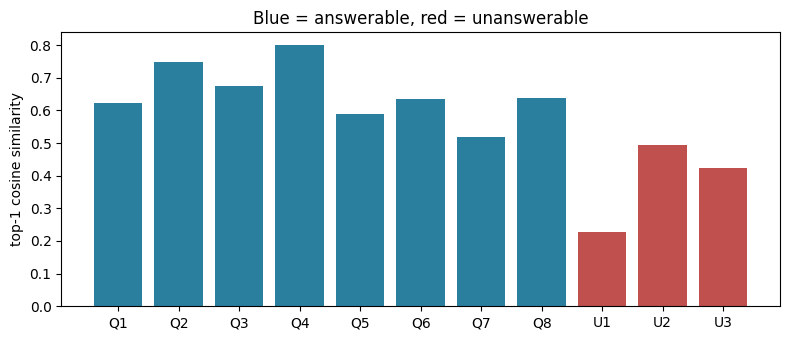

Lowest answerable top-1: 0.518 | highest unanswerable top-1: 0.493
The groups are separated on this small sample; validate any threshold on more questions before using it.


In [31]:
rows = []
for q in labeled_eval + unanswerable_eval:
    top1 = retrieve(q["question"], 1)[0]["score"]
    rows.append({"id": q["id"], "answerable": q["answerable"], "top1_similarity": round(top1, 3)})
score_df = pd.DataFrame(rows)
display(score_df)

if not score_df.empty and score_df.answerable.any() and (~score_df.answerable).any():
    colors = ["#2a7f9e" if a else "#c0504d" for a in score_df.answerable]
    plt.figure(figsize=(8, 3.5))
    plt.bar(score_df.id, score_df.top1_similarity, color=colors)
    plt.ylabel("top-1 cosine similarity"); plt.title("Blue = answerable, red = unanswerable")
    plt.tight_layout(); plt.show()
    lo = score_df[score_df.answerable].top1_similarity.min()
    hi = score_df[~score_df.answerable].top1_similarity.max()
    print(f"Lowest answerable top-1: {lo} | highest unanswerable top-1: {hi}")
    print("The two groups overlap -> no safe threshold on this sample." if hi >= lo else
          "The groups are separated on this small sample; validate any threshold on more questions before using it.")

## STEP 15 — Generation evaluation

Retrieval metrics do not tell us whether the *answer* is good. We evaluate six criteria with a transparent **human rubric** (1–5 scale):

| Criterion | Question asked | 1 (poor) | 3 (acceptable) | 5 (excellent) |
|---|---|---|---|---|
| Factual correctness | Is the answer correct w.r.t. the reference answer and the PDF? | wrong | partly correct | fully correct |
| Relevance | Does it address the question asked? | off-topic | partly | directly |
| Completeness | Are the key points of the reference answer included? | misses most | misses some | all key points |
| Grounding | Is every claim supported by the retrieved passages? | mostly unsupported | some unsupported | fully supported |
| Clarity | Is it understandable and well organised? | confusing | readable | very clear |
| Source accuracy | Do cited source numbers/pages really support the claims? | wrong/invented | partly | all correct |

For **unanswerable** questions, the correct behaviour is to abstain; score *factual correctness* 5 if the system abstains and 1 if it invents an answer.

> **No automatic score proves factual correctness.** The cell below only records formal indicators (abstention heuristic, citation checks, latency). Quality scores come from *you*, entered in the `HUMAN_SCORES` dictionary, ideally with a second reviewer to estimate agreement.

In [32]:
def run_generation_eval(eval_questions, top_k=TOP_K):
    rows = []
    for q in tqdm(eval_questions, desc="Generating answers"):
        res = ask_question(q["question"], top_k=top_k, show=False)
        rows.append({
            "id": q["id"], "question": q["question"], "reference_answer": q["reference_answer"],
            "generated_answer": res["answer"], "answerable": q["answerable"],
            "abstained_(heuristic)": res["abstained"],
            "abstention_behaviour_ok": (res["abstained"] != q["answerable"]),
            "has_citation": res["citation_check"]["has_citation"],
            "invalid_sources": res["citation_check"]["invalid_sources"],
            "unsupported_pages": res["citation_check"]["unsupported_pages"],
            "retrieved_pages": [(s["source"], s["page"]) for s in res["sources"]],
            "retrieval_s": round(res["retrieval_seconds"], 4), "generation_s": round(res["generation_seconds"], 2),
            "model": res["generation_model"],
        })
    return pd.DataFrame(rows)


generation_df = run_generation_eval(labeled_eval + unanswerable_eval)
generation_df.to_csv(ARTIFACT_DIR / "generation_review.csv", index=False)
display(generation_df[["id", "generated_answer", "abstained_(heuristic)", "abstention_behaviour_ok",
                       "has_citation", "invalid_sources", "unsupported_pages", "generation_s"]])

Generating answers:   0%|          | 0/11 [00:00<?, ?it/s]

,id,generated_answer,abstained_(heuristic),abstention_behaviour_ok,has_citation,invalid_sources,unsupported_pages,generation_s
0,Q1,The guide uses 900 characters as the chunk siz...,False,True,True,[],[],3.64
1,Q2,"According to [1] and [2], the IndexFlatIP FAIS...",False,True,True,[],[],8.96
2,Q3,Mean Reciprocal Rank (MRR) is computed by calc...,False,True,True,[],[],8.99
3,Q4,Precision@k and Recall@k are defined as follow...,False,True,True,[],[],5.24
4,Q5,The guide demonstrates Qwen/Qwen2.5-3B-Instruc...,False,True,True,[],[],3.54
5,Q6,"When the text extracted from a PDF is empty, a...",False,True,True,[],[],4.26
6,Q7,The provided documents do not contain enough i...,True,False,False,[],[],2.47
7,Q8,The provided documents do not contain enough i...,True,False,True,[],[],3.84
8,U1,The provided documents do not contain enough i...,True,True,False,[],[],2.83
9,U2,The provided documents do not contain enough i...,True,True,False,[],[],2.36


In [33]:
# >>> OPTIONAL HUMAN EVALUATION: after reading generated answers (above) next to the reference answers and the PDF,
# >>> fill in your own 1-5 scores, e.g.
# HUMAN_SCORES = {"Q1": {"factual": 5, "relevance": 5, "completeness": 4, "grounding": 5, "clarity": 4, "source_accuracy": 5}, ...}
HUMAN_SCORES = {}

CRITERIA = ["factual", "relevance", "completeness", "grounding", "clarity", "source_accuracy"]

if HUMAN_SCORES:
    scores_df = pd.DataFrame.from_dict(HUMAN_SCORES, orient="index")[CRITERIA]
    assert scores_df.apply(lambda col: col.between(1, 5)).all().all(), "scores must be between 1 and 5"
    display(scores_df)
    print("Mean score per criterion:"); display(scores_df.mean().round(2).to_frame("mean (1-5)"))
    scores_df.mean().plot(kind="bar", ylim=(0, 5), figsize=(7, 3.5), color="#2a7f9e", title="Human evaluation (mean, 1-5)")
    plt.tight_layout(); plt.show()
else:
    print("HUMAN_SCORES is empty: no quality score is reported (none is invented).")

if len(generation_df):
    ab = generation_df[~generation_df.answerable]
    an = generation_df[generation_df.answerable]
    print(f"\nAutomatic indicators (heuristic, not proof of correctness):")
    print(f"  unanswerable questions with abstention : {int(ab['abstention_behaviour_ok'].sum())}/{len(ab)}")
    print(f"  answerable questions NOT wrongly refused: {int(an['abstention_behaviour_ok'].sum())}/{len(an)}")
    print(f"  answers containing a citation          : {int(generation_df['has_citation'].sum())}/{len(generation_df)}")

HUMAN_SCORES is empty: no quality score is reported (none is invented).

Automatic indicators (heuristic, not proof of correctness):
  unanswerable questions with abstention : 2/3
  answerable questions NOT wrongly refused: 6/8
  answers containing a citation          : 8/11


## STEP 16 — Reproducible experiments and comparisons

**Protocol.** The same labelled questions, embedding model and code are used for every configuration. Starting from the baseline (**900 / 150 / top-K 4**) we change **one parameter at a time**:

* **chunk size** ∈ {600, 900, 1200} with overlap fixed at 150;
* **overlap** ∈ {0, 150, 300} with chunk size fixed at 900;
* **Top-K** ∈ {2, 4, 6, 8} with the baseline index.

For completeness the table also contains the course's paired variants A (600/100) and C (1200/200), which change *two* parameters at once and therefore cannot attribute an effect to a single factor. We record Precision@K, Recall@K, MRR, retrieval latency (mean per query), index build time and the number of chunks. Generation latency is measured separately for the baseline below.

In [34]:
EXPERIMENT_CONFIGS = [
    ("baseline", 900, 150),
    ("chunk_size", 600, 150), ("chunk_size", 1200, 150),
    ("overlap", 900, 0), ("overlap", 900, 300),
    ("course_variant_A", 600, 100), ("course_variant_C", 1200, 200),
]
EXPERIMENT_K_VALUES = [2, 4, 6, 8]


def run_experiments(page_list, eval_questions, configs, k_values, model):
    rows = []
    _ = retrieve(eval_questions[0]["question"], 1, kb=ACTIVE_KB, model=model)        # warm-up (excluded from timings)
    for name, size, overlap in tqdm(configs, desc="Configurations"):
        t0 = time.perf_counter()
        kb = build_knowledge_base(page_list, size, overlap, model, show_progress=False)
        build_s = time.perf_counter() - t0
        for k in k_values:
            per_q, latencies = [], []
            for q in eval_questions:
                t = time.perf_counter()
                res = retrieve(q["question"], k, kb=kb, model=model)
                latencies.append(time.perf_counter() - t)
                keys = [(r["source"], r["page"]) for r in res]
                relevant = {(p["source"], p["page"]) for p in q["relevant_pages"]}
                per_q.append(evaluate_ranking(keys, relevant, k))
            rows.append({
                "group": name, "chunk_size": size, "overlap": overlap, "top_k": k, "n_chunks": len(kb.chunks),
                "precision@k": np.mean([m["precision"] for m in per_q]),
                "recall@k": np.mean([m["recall"] for m in per_q]),
                "MRR": np.mean([m["rr"] for m in per_q]),
                "retrieval_ms": 1000 * np.mean(latencies), "index_build_s": build_s,
            })
    return pd.DataFrame(rows)


if labeled_eval:
    experiments_df = run_experiments(pages, labeled_eval, EXPERIMENT_CONFIGS, EXPERIMENT_K_VALUES, embedding_model)
    experiments_df.to_csv(ARTIFACT_DIR / "experiments.csv", index=False)
    display(experiments_df.round(3))
else:
    experiments_df = pd.DataFrame()
    print("Experiments need labelled questions that match your documents (see Step 13).")

Configurations:   0%|          | 0/7 [00:00<?, ?it/s]

,group,chunk_size,overlap,top_k,n_chunks,precision@k,recall@k,MRR,retrieval_ms,index_build_s
0,baseline,900,150,2,482,0.188,0.250,0.375,13.551,1.015
1,baseline,900,150,4,482,0.219,0.479,0.521,13.553,1.015
2,baseline,900,150,6,482,0.188,0.583,0.521,14.196,1.015
3,baseline,900,150,8,482,0.156,0.625,0.521,13.506,1.015
4,chunk_size,600,150,2,633,0.188,0.250,0.375,15.639,1.341
5,chunk_size,600,150,4,633,0.250,0.510,0.562,13.643,1.341
6,chunk_size,600,150,6,633,0.208,0.615,0.562,13.636,1.341
7,chunk_size,600,150,8,633,0.156,0.615,0.562,16.212,1.341
8,chunk_size,1200,150,2,420,0.188,0.250,0.375,19.210,0.939
9,chunk_size,1200,150,4,420,0.219,0.479,0.521,18.634,0.939


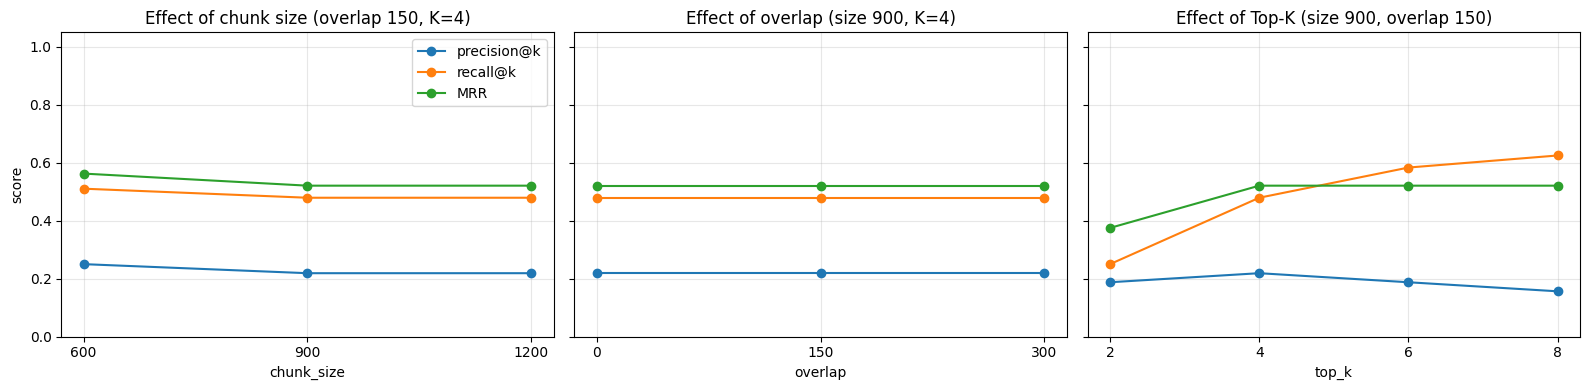

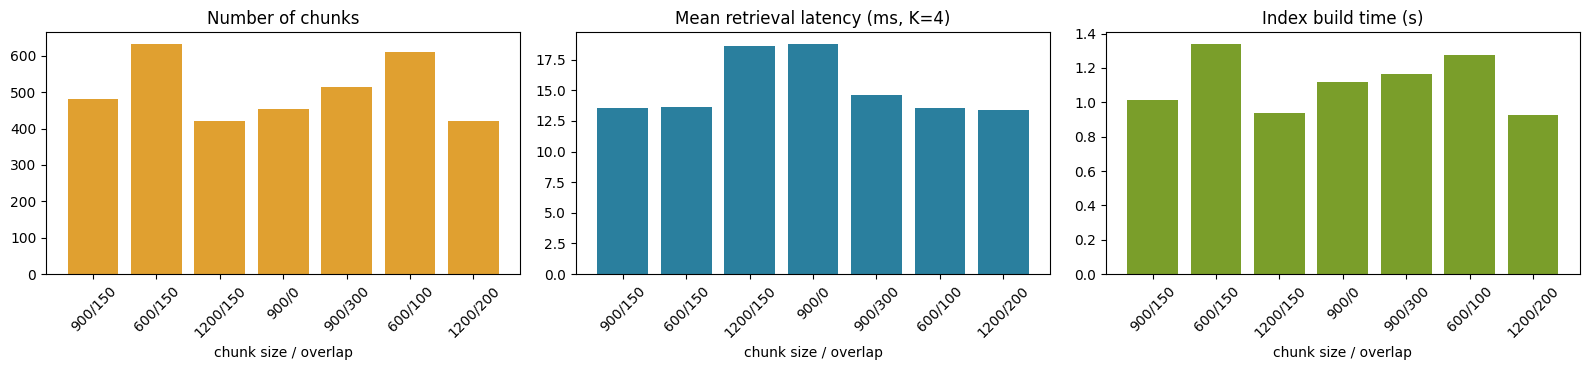

In [35]:
if not experiments_df.empty:
    base = dict(chunk_size=900, overlap=150, top_k=4)
    cols = ["precision@k", "recall@k", "MRR"]

    size_df = experiments_df[(experiments_df.overlap == 150) & (experiments_df.top_k == 4) &
                             experiments_df.group.isin(["baseline", "chunk_size"])].sort_values("chunk_size")
    ov_df = experiments_df[(experiments_df.chunk_size == 900) & (experiments_df.top_k == 4) &
                           experiments_df.group.isin(["baseline", "overlap"])].sort_values("overlap")
    k_df = experiments_df[(experiments_df.group == "baseline")].sort_values("top_k")

    fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
    for ax, df, x, title in [(axes[0], size_df, "chunk_size", "Effect of chunk size (overlap 150, K=4)"),
                             (axes[1], ov_df, "overlap", "Effect of overlap (size 900, K=4)"),
                             (axes[2], k_df, "top_k", "Effect of Top-K (size 900, overlap 150)")]:
        for c in cols:
            ax.plot(df[x], df[c], marker="o", label=c)
        ax.set_title(title); ax.set_xlabel(x); ax.set_xticks(df[x]); ax.set_ylim(0, 1.05); ax.grid(alpha=0.3)
    axes[0].set_ylabel("score"); axes[0].legend()
    plt.tight_layout(); plt.show()

    cfg_k4 = experiments_df[experiments_df.top_k == 4].copy()
    cfg_k4["config"] = cfg_k4.chunk_size.astype(str) + "/" + cfg_k4.overlap.astype(str)
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
    ax[0].bar(cfg_k4.config, cfg_k4.n_chunks, color="#e0a030"); ax[0].set_title("Number of chunks")
    ax[1].bar(cfg_k4.config, cfg_k4["retrieval_ms"], color="#2a7f9e"); ax[1].set_title("Mean retrieval latency (ms, K=4)")
    ax[2].bar(cfg_k4.config, cfg_k4["index_build_s"], color="#7a9e2a"); ax[2].set_title("Index build time (s)")
    for a in ax:
        a.set_xlabel("chunk size / overlap"); a.tick_params(axis="x", rotation=45)
    plt.tight_layout(); plt.show()

In [36]:
def measure_generation_latency(n_questions=3, top_k=TOP_K):
    if gen_model is None or not labeled_eval:
        print("Generation model or labelled questions unavailable."); return None
    times = []
    for q in labeled_eval[:n_questions]:
        res = ask_question(q["question"], top_k=top_k, show=False)
        times.append(res["generation_seconds"])
    print(f"Mean generation latency over {len(times)} questions with {ACTIVE_GENERATION_MODEL} "
          f"on {DEVICE}: {np.mean(times):.1f} s (top_k={top_k}, max_new_tokens={MAX_NEW_TOKENS})")
    return float(np.mean(times))


baseline_generation_latency = measure_generation_latency()

Mean generation latency over 3 questions with Qwen/Qwen2.5-3B-Instruct on cuda: 7.2 s (top_k=4, max_new_tokens=300)


### How to interpret the experiments (read after running)

* **Compare configurations only with the numbers you obtained.** With a small evaluation set (≈ 8 questions) one question changes a mean by 12.5 points, so differences of a few points are within noise; no statistical significance is claimed.
* **Page-level labels and short pages.** For slide-like PDFs each page is usually one chunk, so chunk size and overlap may change little; long continuous text is where chunking matters.
* **Embedding truncation.** Because the baseline embedder only reads its first `max_seq_length` word-pieces (Step 6), larger chunks may be partly invisible to retrieval. Check `truncation_report` for each size before concluding that "bigger is worse/better".
* **Top-K trade-off.** Recall can only increase with K, while Precision@K usually decreases; MRR depends on the rank of the first hit, so it is non-decreasing with K but saturates quickly. A larger K also lengthens the LLM prompt and generation time.
* **Limitations of this study:** a single corpus, labels written by one annotator, no retrieval re-ranking, no hybrid (BM25 + dense) retrieval, and generation quality evaluated separately by hand (Step 15).

## STEP 17 — Troubleshooting

| Problem | Likely cause | Practical solution |
|---|---|---|
| **Empty PDF extraction** (`0 pages with text`) | scanned/image PDF, protected or corrupted file | Check the OCR warning in Step 3; run OCR (`ocrmypdf`, Tesseract) and upload the OCR'd PDF; re-save a damaged PDF. |
| **Scanned PDFs needing OCR** | pages are images | PyMuPDF does not OCR. Use OCR first; never assume a scanned file was indexed. |
| **Irrelevant retrieved passages** | bad extraction order, chunks too large/small, weak embedding model for the domain/language | Inspect `show_retrieved`, clean the text, test other chunk sizes (Step 16), try another embedding model, add a re-ranker or hybrid BM25 search. |
| **Hallucinated answers** | missing evidence, ignored instructions, too much noise in context | Keep the strict system prompt, lower `top_k`, set `MIN_SIMILARITY`, test unanswerable questions, check citations, use a larger model, verify against the PDF. |
| **`CUDA out of memory` / RAM exhausted** | model too large for the runtime | Use a GPU runtime, restart the runtime to free memory, use the 1.5B fallback (`ALLOW_FALLBACK`), shorten `top_k`/chunk size or `MAX_NEW_TOKENS`, or use a quantised model (e.g. `bitsandbytes` 4-bit). |
| **Slow generation** | CPU runtime, long context, many new tokens | Switch to GPU, reduce `top_k` and `MAX_NEW_TOKENS`, use a smaller model; time extraction, embedding, retrieval and generation separately (as in Step 16). |
| **FAISS index/metadata mismatch** | metadata edited, partially rebuilt or loaded from a different run | `validate_knowledge_base` raises an error; rebuild vectors *and* `chunks.json` together; never reorder either one alone. |
| **Missing model dependencies** | wrong package versions, `accelerate` missing for `device_map`, no internet for model download | Re-run the install cell and restart the runtime; make sure Internet access is enabled; check the exact error message and the model card. |
| **Query and index use different embedding models** | index built with another model | `load_knowledge_base` checks the stored model name; rebuild the index. |

## STEP 18 — Limitations and responsible use

* **Retrieval errors.** A passage can be semantically similar without answering the question; a relevant passage can be missed (vocabulary gap, truncation by the embedder, poor extraction). High similarity ≠ relevance.
* **Missing information.** If the knowledge base lacks the answer, the system must abstain. Small LLMs may still produce a plausible but unsupported reply; abstention must be tested (Steps 13–15).
* **Generation errors.** The model may misread, over-generalise or mis-cite the context, even when the right passage was retrieved. Good retrieval is necessary, not sufficient.
* **Document quality.** Outdated, contradictory or badly extracted (tables, equations, columns, scans) content directly degrades answers.
* **Privacy.** Documents and questions are processed on the Colab virtual machine (Google infrastructure) and models are downloaded from Hugging Face. Do not upload confidential, personal or restricted documents unless this complies with your institution's rules; remove uploaded files and artifacts when done. Never commit PDFs, indexes built from private documents, or tokens to GitHub.
* **Licenses.** The project code is MIT-licensed, but PyMuPDF (AGPL/commercial), the embedding model, the Qwen models and every library keep **their own licenses**: read the model cards before reuse or redistribution.
* **Human verification.** Answers must be checked against the cited PDF page. For high-impact decisions (medical, legal, financial, academic grading) require qualified human review.

**Why RAG helps but cannot guarantee correctness.** RAG reduces reliance on the model's internal (possibly outdated or wrong) knowledge by placing relevant, verifiable evidence in the prompt and exposing source names and pages. It does not guarantee correctness because every stage can fail (extraction → chunking → embedding → retrieval → generation), and the generator may still ignore or distort the evidence.

## Final step — Export run summary

Saves the index, metadata and a small JSON file describing the exact configuration of this run (for the README results section and for reproducibility). Download the files you want to keep from the Colab file browser; **do not publish artifacts built from private documents**.

In [37]:
save_knowledge_base(ACTIVE_KB)

run_summary = {
    "date": time.strftime("%Y-%m-%d %H:%M:%S"),
    "documents": [p.name for p in pdf_paths],
    "n_pages_with_text": len(pages), "n_chunks": len(ACTIVE_KB.chunks),
    "chunk_size": CHUNK_SIZE, "overlap": CHUNK_OVERLAP, "top_k": TOP_K,
    "embedding_model": EMBEDDING_MODEL_NAME,
    "generation_model_requested": GENERATION_MODEL_NAME,
    "generation_model_used": ACTIVE_GENERATION_MODEL,
    "device": DEVICE, "torch": torch.__version__,
    "n_labelled_eval_questions": len(labeled_eval), "n_unanswerable_questions": len(unanswerable_eval),
}
with open(ARTIFACT_DIR / "run_summary.json", "w", encoding="utf-8") as f:
    json.dump(run_summary, f, indent=2)
print(json.dumps(run_summary, indent=2))
print("\nFiles in", ARTIFACT_DIR, ":", sorted(p.name for p in ARTIFACT_DIR.iterdir()))

Saved index + metadata to /content/artifacts
{
  "date": "2026-11-25 10:00:31",
  "documents": [
    "1.-La-d\u00e9finition-du-domaine-RI_chap1.pdf",
    "2.-introduction-RI.pdf",
    "3.-modeles-RI-1.pdf",
    "3.1-difference-entre-mod\u00e8le-bool\u00e9en-et-le-mod\u00e8le-vectoriel.pdf",
    "4.-modele-p-norme.pdf",
    "ComprendreleRAGVersuneIAquiinterrogevosdocumentsintelligemment (1).pdf",
    "ComprendreleRAGVersuneIAquiinterrogevosdocumentsintelligemment.pdf",
    "RAG (1).pdf",
    "RAG.pdf",
    "RAGEXPLANATION (1).pdf",
    "RAGEXPLANATION.pdf",
    "RAG_Detailed (1).pdf",
    "RAG_Detailed.pdf"
  ],
  "n_pages_with_text": 302,
  "n_chunks": 482,
  "chunk_size": 900,
  "overlap": 150,
  "top_k": 4,
  "embedding_model": "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
  "generation_model_requested": "Qwen/Qwen2.5-3B-Instruct",
  "generation_model_used": "Qwen/Qwen2.5-3B-Instruct",
  "device": "cuda",
  "torch": "2.14.1+cu130",
  "n_labelled_eval_questions": 8,
 